# Naive vs SDPA

B=2, D=128, L=2, H=4, V=50257. MPS, FP32, dropout=0.
T=64/128/256; three repeats per backend. We measure the whole GPT, including the LM head and loss.

## Time

5 warmups, 1000 samples. Forward includes loss and autograd; forward_backward adds backward; optimizer_step also clears gradients and runs AdamW.
Tokens/s = B*T / mean time. Results are already in `results/`.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

root = Path.cwd()
if root.name == "03_attention":
    root = root.parent.parent
results_dir = root / "experiments/03_attention/results"
configs = ["t64", "baseline", "t256"]
repeats = ["repeat-01", "repeat-02", "repeat-03"]
backends = ["naive", "sdpa"]
workloads = ["forward", "forward_backward", "optimizer_step"]
colors = {"naive": "C0", "sdpa": "C1"}
styles = {"repeat-01": "-", "repeat-02": "--", "repeat-03": ":"}

In [2]:
rows = []
for repeat in repeats:
    for backend in backends:
        for config in configs:
            path = results_dir / repeat / backend / f"{config}.json"
            with path.open() as file:
                result = json.load(file)
            for workload, measurement in result["measurements"].items():
                rows.append({
                    "repeat": repeat, "backend": backend,
                    "T": result["config"]["benchmark"]["sequence_length"],
                    "workload": workload,
                    "mean_ms": measurement["mean_seconds"] * 1000,
                    "median_ms": measurement["median_seconds"] * 1000,
                    "tokens_per_second": measurement["tokens_per_second"],
                })

timings = pd.DataFrame(rows).sort_values(["workload", "T", "repeat", "backend"])
timings.round(2)

,repeat,backend,T,workload,mean_ms,median_ms,tokens_per_second
0,repeat-01,naive,64,forward,10.63,10.74,12039.82
9,repeat-01,sdpa,64,forward,10.32,10.34,12399.64
18,repeat-02,naive,64,forward,8.92,9.40,14357.02
27,repeat-02,sdpa,64,forward,10.09,10.89,12680.51
36,repeat-03,naive,64,forward,9.79,9.91,13071.11
45,repeat-03,sdpa,64,forward,9.73,10.43,13155.23
3,repeat-01,naive,128,forward,16.52,16.56,15499.81
12,repeat-01,sdpa,128,forward,17.49,18.64,14634.22
21,repeat-02,naive,128,forward,12.25,13.22,20896.29
30,repeat-02,sdpa,128,forward,14.44,13.80,17724.10


Speedup = naive / SDPA time. Above 1 means SDPA is faster.

In [3]:
naive = timings[timings["backend"] == "naive"]
sdpa = timings[timings["backend"] == "sdpa"]
comparison = naive.merge(sdpa, on=["repeat", "T", "workload"],
                         suffixes=("_naive", "_sdpa"))
comparison["mean_speedup"] = comparison["mean_ms_naive"] / comparison["mean_ms_sdpa"]
comparison["median_speedup"] = comparison["median_ms_naive"] / comparison["median_ms_sdpa"]
comparison[["repeat", "T", "workload", "mean_speedup", "median_speedup"]].round(3)

,repeat,T,workload,mean_speedup,median_speedup
0,repeat-01,64,forward,1.030,1.038
1,repeat-02,64,forward,0.883,0.863
2,repeat-03,64,forward,1.006,0.951
3,repeat-01,128,forward,0.944,0.888
4,repeat-02,128,forward,0.848,0.957
5,repeat-03,128,forward,1.031,1.008
6,repeat-01,256,forward,0.664,0.668
7,repeat-02,256,forward,0.882,0.900
8,repeat-03,256,forward,0.989,0.980
9,repeat-01,64,forward_backward,1.001,0.997


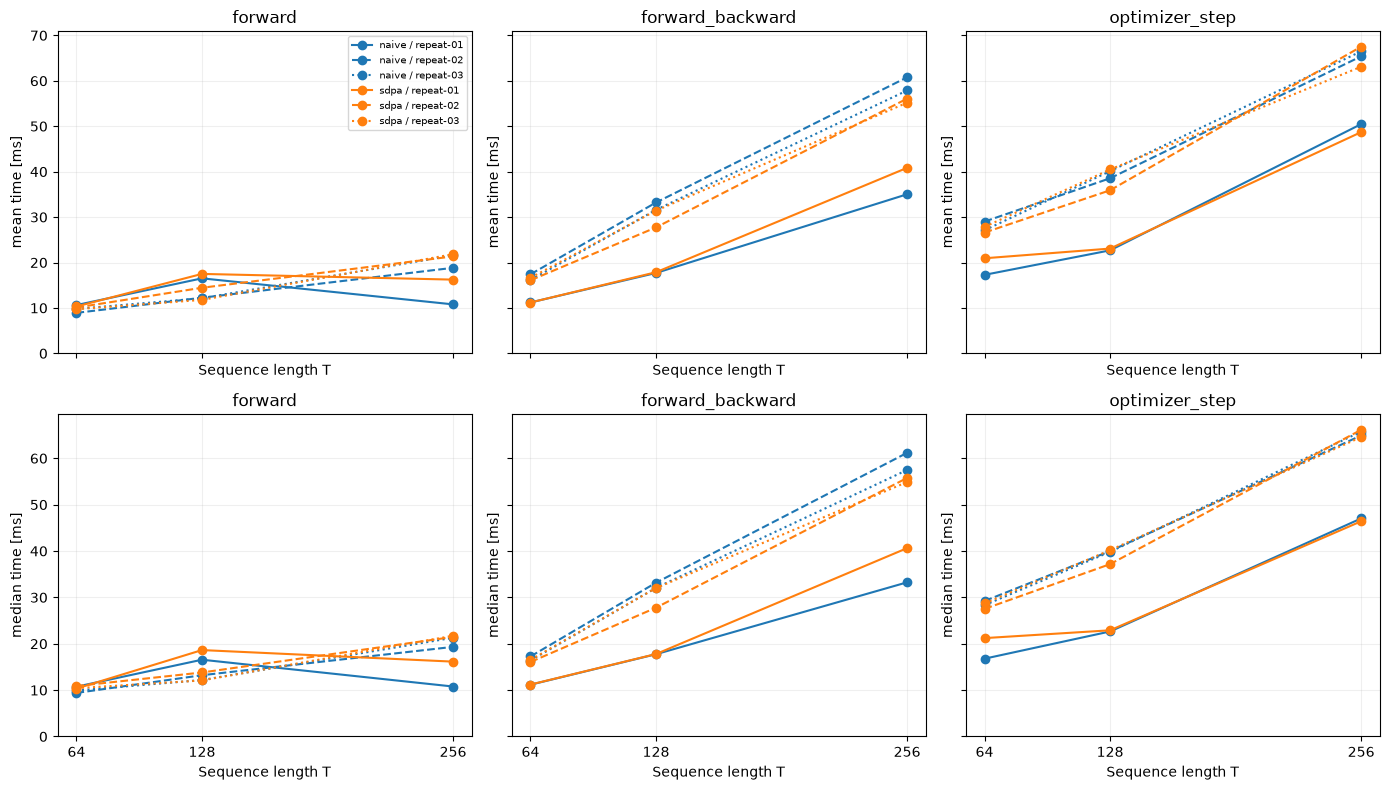

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(14, 8), sharex=True, sharey="row")
for row, metric in enumerate(["mean_ms", "median_ms"]):
    for col, workload in enumerate(workloads):
        ax = axes[row, col]
        data = timings[timings["workload"] == workload]
        for (backend, repeat), points in data.groupby(["backend", "repeat"]):
            points = points.sort_values("T")
            ax.plot(points["T"], points[metric], marker="o", color=colors[backend],
                    linestyle=styles[repeat], label=f"{backend} / {repeat}")
        ax.set_title(workload)
        ax.set_xlabel("Sequence length T")
        ax.set_ylabel(f"{metric.split('_')[0]} time [ms]")
        ax.set_xticks([64, 128, 256])
        ax.grid(alpha=0.2)
    axes[row, 0].set_ylim(0, timings[metric].max() * 1.05)
axes[0, 0].legend(fontsize=7)
fig.tight_layout()
plt.show()

## Memory

Separate runs: 1000 AdamW steps. Below: memory after forward at step 1000.
`tensor_MiB` counts live tensors; `driver_MiB` includes cache too. Neither is a peak.

In [5]:
rows = []
for repeat in repeats:
    for backend in backends:
        for config in configs:
            path = results_dir / repeat / backend / f"{config}_memory.json"
            with path.open() as file:
                result = json.load(file)
            for snapshot in result["snapshots"]:
                rows.append({
                    "repeat": repeat, "backend": backend,
                    "T": result["config"]["sequence_length"],
                    "step": snapshot["step"], "stage": snapshot["stage"],
                    "tensor_MiB": snapshot["tensor_bytes"] / 2**20,
                    "driver_MiB": snapshot["driver_bytes"] / 2**20,
                })

memory = pd.DataFrame(rows)
metrics = ["tensor_MiB", "driver_MiB"]

In [6]:
after_forward = memory[(memory["step"] == 1000) & (memory["stage"] == "after_forward")]
memory_comparison = after_forward.pivot(index=["T", "repeat"], columns="backend", values="tensor_MiB")
memory_comparison["difference_MiB"] = memory_comparison["naive"] - memory_comparison["sdpa"]
memory_comparison.round(3)

backend          naive     sdpa  difference_MiB
T   repeat                                     
64  repeat-01  132.807  132.299           0.508
    repeat-02  132.807  132.299           0.508
    repeat-03  132.807  132.299           0.508
128 repeat-01  185.712  185.181           0.531
    repeat-02  185.712  185.181           0.531
    repeat-03  185.712  185.181           0.531
256 repeat-01  293.071  292.446           0.625
    repeat-02  293.071  292.446           0.625
    repeat-03  293.071  292.446           0.625

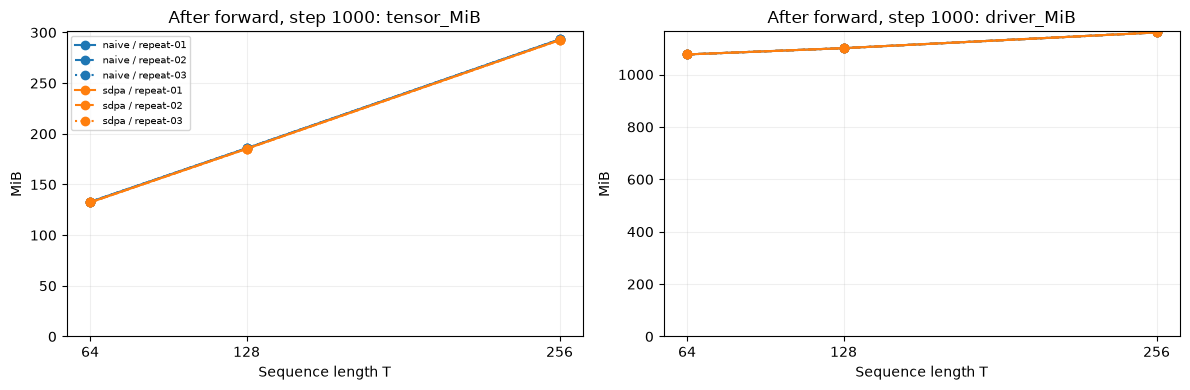

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharex=True)
for ax, metric in zip(axes, metrics):
    for (backend, repeat), points in after_forward.groupby(["backend", "repeat"]):
        points = points.sort_values("T")
        ax.plot(points["T"], points[metric], marker="o", color=colors[backend],
                linestyle=styles[repeat], label=f"{backend} / {repeat}")
    ax.set_title(f"After forward, step 1000: {metric}")
    ax.set_xlabel("Sequence length T")
    ax.set_ylabel("MiB")
    ax.set_xticks([64, 128, 256])
    ax.set_ylim(bottom=0)
    ax.grid(alpha=0.2)
axes[0].legend(fontsize=7)
fig.tight_layout()
plt.show()

## What happened?

No consistent speedup across repeats. We always ran naive before SDPA.

The memory difference is real but small. On this Mac (PyTorch 2.14, autograd on), an operator trace showed `_scaled_dot_product_attention_math`. Both versions keep the full attention matrix for backward — this is not FlashAttention.

At T=256, naive uses 0.625 MiB more: 0.5 MiB of model masks plus 0.125 MiB of boolean masks saved for backward. Driver allocations are equal.

[PyTorch backend selection](https://github.com/pytorch/pytorch/blob/08187d9e0fba026dc8217405802ab5381dc88d90/aten/src/ATen/native/transformers/attention.cpp).

# Longer sequences, smaller vocabulary

T=256/512/1024, V=4096, context=1024. B=2, D=128, L=2, H=4 stay fixed.
A smaller LM head makes attention a larger part of the work. This is a separate series, not a speedup over the old configs.

We compare forward + loss with autograd on/off. No backward or optimizer step here; this is not token-by-token generation.
20 warmups, 1000 samples, three repeats. Run: `bash experiments/03_attention/run_long.sh` (requires unused output paths).

In [8]:
long_dir = results_dir / "long"
rows = []
for repeat in repeats:
    for mode in ["grad", "no_grad"]:
        for backend in backends:
            for T in [256, 512, 1024]:
                with (long_dir / repeat / mode / backend / f"t{T}.json").open() as file:
                    result = json.load(file)
                measurement = result["measurements"]["forward"]
                rows.append({
                    "repeat": repeat, "mode": mode, "backend": backend, "T": T,
                    "mean_ms": measurement["mean_seconds"] * 1000,
                    "median_ms": measurement["median_seconds"] * 1000,
                })
long_times = pd.DataFrame(rows)
long_times.round(3)

,repeat,mode,backend,T,mean_ms,median_ms
0,repeat-01,grad,naive,256,7.701,5.960
1,repeat-01,grad,naive,512,8.594,8.486
2,repeat-01,grad,naive,1024,16.295,16.417
3,repeat-01,grad,sdpa,256,7.219,5.378
4,repeat-01,grad,sdpa,512,6.223,5.043
5,repeat-01,grad,sdpa,1024,16.464,16.458
6,repeat-01,no_grad,naive,256,7.570,5.667
7,repeat-01,no_grad,naive,512,6.833,5.691
8,repeat-01,no_grad,naive,1024,16.326,16.435
9,repeat-01,no_grad,sdpa,256,2.093,1.630


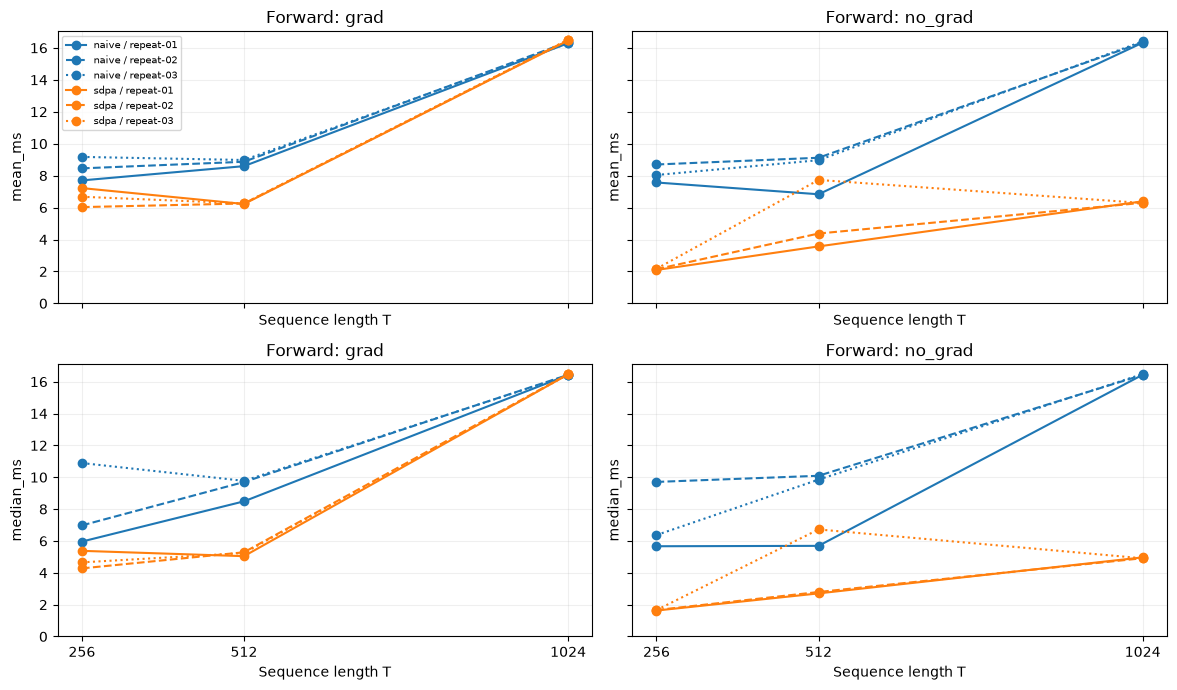

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=True, sharey="row")
for row, metric in enumerate(["mean_ms", "median_ms"]):
    for col, mode in enumerate(["grad", "no_grad"]):
        ax = axes[row, col]
        data = long_times[long_times["mode"] == mode]
        for (backend, repeat), points in data.groupby(["backend", "repeat"]):
            points = points.sort_values("T")
            ax.plot(points["T"], points[metric], marker="o", color=colors[backend],
                    linestyle=styles[repeat], label=f"{backend} / {repeat}")
        ax.set_title(f"Forward: {mode}")
        ax.set_ylabel(metric)
        ax.set_xlabel("Sequence length T")
        ax.set_xticks([256, 512, 1024])
        ax.set_ylim(bottom=0)
        ax.grid(alpha=0.2)
axes[0, 0].legend(fontsize=7)
fig.tight_layout()
plt.show()

## Memory

One separate 1000-forward run per combination. No optimizer or gradients from backward.
`forward_MiB` = after forward minus before forward: memory still held by outputs and the graph, not temporary peak memory. With no_grad, attention intermediates may already be gone.

In [10]:
rows = []
for mode in ["grad", "no_grad"]:
    for backend in backends:
        for T in [256, 512, 1024]:
            with (long_dir / "memory" / mode / backend / f"t{T}.json").open() as file:
                result = json.load(file)
            before = {s["step"]: s["tensor_bytes"] for s in result["snapshots"]
                      if s["stage"] == "before_forward"}
            for s in result["snapshots"]:
                if s["stage"] == "after_forward":
                    rows.append({
                        "mode": mode, "backend": backend, "T": T, "step": s["step"],
                        "tensor_MiB": s["tensor_bytes"] / 2**20,
                        "driver_MiB": s["driver_bytes"] / 2**20,
                        "forward_MiB": (s["tensor_bytes"] - before[s["step"]]) / 2**20,
                    })
long_memory = pd.DataFrame(rows)
last = long_memory[long_memory["step"] == 1000]
last.pivot(index=["mode", "T"], columns="backend",
           values=["tensor_MiB", "forward_MiB", "driver_MiB"]).round(3)

tensor_MiB          forward_MiB          driver_MiB          
backend           naive     sdpa       naive     sdpa      naive      sdpa
mode    T                                                                 
grad    256      40.668   32.543      28.647   28.522     82.703    50.703
        512      78.073   69.573      66.043   65.543   1106.703  1106.703
        1024    176.131  166.131     164.086  162.086   1082.703  1082.703
no_grad 256      20.022   12.022       8.000    8.000     74.703    42.703
        512      28.030   20.030      16.000   16.000   1066.703  1066.703
        1024     44.045   36.045      32.000   32.000   1066.703  1066.703

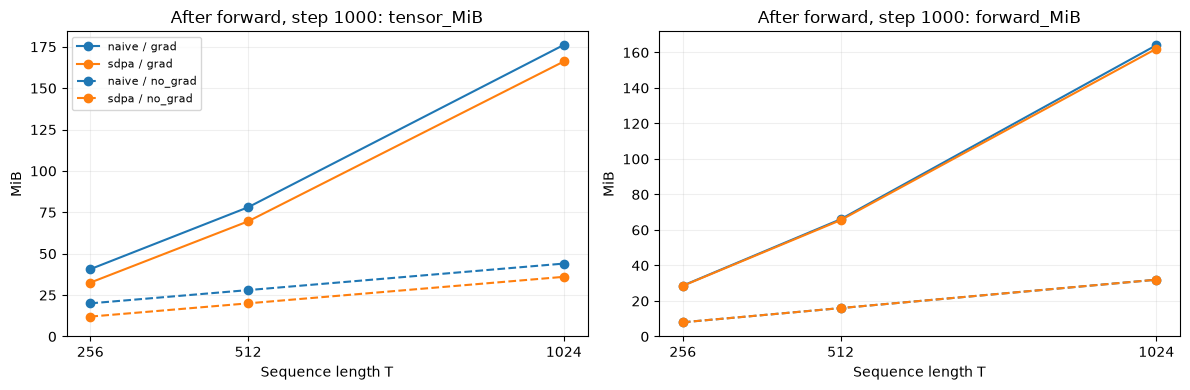

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, metric in zip(axes, ["tensor_MiB", "forward_MiB"]):
    for (mode, backend), points in last.groupby(["mode", "backend"]):
        points = points.sort_values("T")
        ax.plot(points["T"], points[metric], marker="o", color=colors[backend],
                linestyle="-" if mode == "grad" else "--", label=f"{backend} / {mode}")
    ax.set_title(f"After forward, step 1000: {metric}")
    ax.set_xlabel("Sequence length T")
    ax.set_ylabel("MiB")
    ax.set_xticks([256, 512, 1024])
    ax.set_ylim(bottom=0)
    ax.grid(alpha=0.2)
axes[0].legend(fontsize=8)
fig.tight_layout()
plt.show()

## Short takeaways

At T=1024, SDPA without autograd was 2.55–2.61x faster by mean time across three repeats. With autograd, the two versions took almost the same time. T=512 had more variation.

At T=1024, forward retained 164.09 MiB (naive) vs 162.09 MiB (SDPA) with autograd. Without autograd, both retained 32 MiB. The extra 8 MiB in naive total memory comes from fixed masks.

Faster execution does not have to leave less memory allocated after the call. These snapshots do not show temporary peaks.

# Attention alone

Does the rest of GPT hide the speedup? Here we only measure causal attention on Q/K/V.
B=2, H=4, head_dim=32, FP32, MPS; T=512/1024/2048. No projections, LM head, loss or optimizer.

- `forward`: autograd off.
- `forward_backward`: forward + backward with a ready output gradient.
- Inputs and the naive causal mask are allocated before timing; gradient reset and output release are outside timing too.

20 warmups, 1000 samples, three separate runs. Repeat 2 runs SDPA first.
Outputs and Q/K/V gradients are checked before timing. From the repo root: `bash experiments/03_attention/run_core.sh` (uses new files, refuses to overwrite results).


In [12]:
rows = []
for repeat in repeats:
    for path in sorted((results_dir / "core" / repeat).glob("*/*/t*.json")):
        with path.open() as file:
            result = json.load(file)
        rows.append({
            "repeat": repeat, "T": result["T"],
            "backend": result["backend"], "workload": result["workload"],
            "mean_ms": result["mean_ms"], "median_ms": result["median_ms"],
            "saved_total_MiB": result["saved_for_backward"]["total_bytes"] / 2**20,
            "saved_extra_MiB": result["saved_for_backward"]["extra_bytes"] / 2**20,
        })
core_times = pd.DataFrame(rows)
core_comparison = core_times[core_times.backend == "naive"].merge(
    core_times[core_times.backend == "sdpa"],
    on=["repeat", "T", "workload"], suffixes=("_naive", "_sdpa"),
)
for metric in ["mean", "median"]:
    core_comparison[f"{metric}_speedup"] = (
        core_comparison[f"{metric}_ms_naive"] / core_comparison[f"{metric}_ms_sdpa"]
    )
core_comparison[["T", "workload", "repeat", "mean_ms_naive", "mean_ms_sdpa",
                 "median_ms_naive", "median_ms_sdpa", "mean_speedup", "median_speedup"]].round(3)


,T,workload,repeat,mean_ms_naive,mean_ms_sdpa,median_ms_naive,median_ms_sdpa,mean_speedup,median_speedup
0,1024,forward,repeat-01,4.000,1.270,3.862,1.142,3.149,3.383
1,2048,forward,repeat-01,13.573,1.540,13.561,1.445,8.815,9.387
2,512,forward,repeat-01,1.685,0.834,1.353,0.796,2.021,1.700
3,1024,forward_backward,repeat-01,9.215,8.368,9.193,8.299,1.101,1.108
4,2048,forward_backward,repeat-01,43.582,40.623,45.364,39.769,1.073,1.141
5,512,forward_backward,repeat-01,3.760,3.119,3.816,2.982,1.205,1.280
6,1024,forward,repeat-02,5.546,0.794,4.457,0.531,6.981,8.401
7,2048,forward,repeat-02,17.625,1.822,17.665,1.430,9.676,12.351
8,512,forward,repeat-02,2.330,0.495,1.475,0.322,4.705,4.582
9,1024,forward_backward,repeat-02,12.570,11.399,13.252,12.280,1.103,1.079


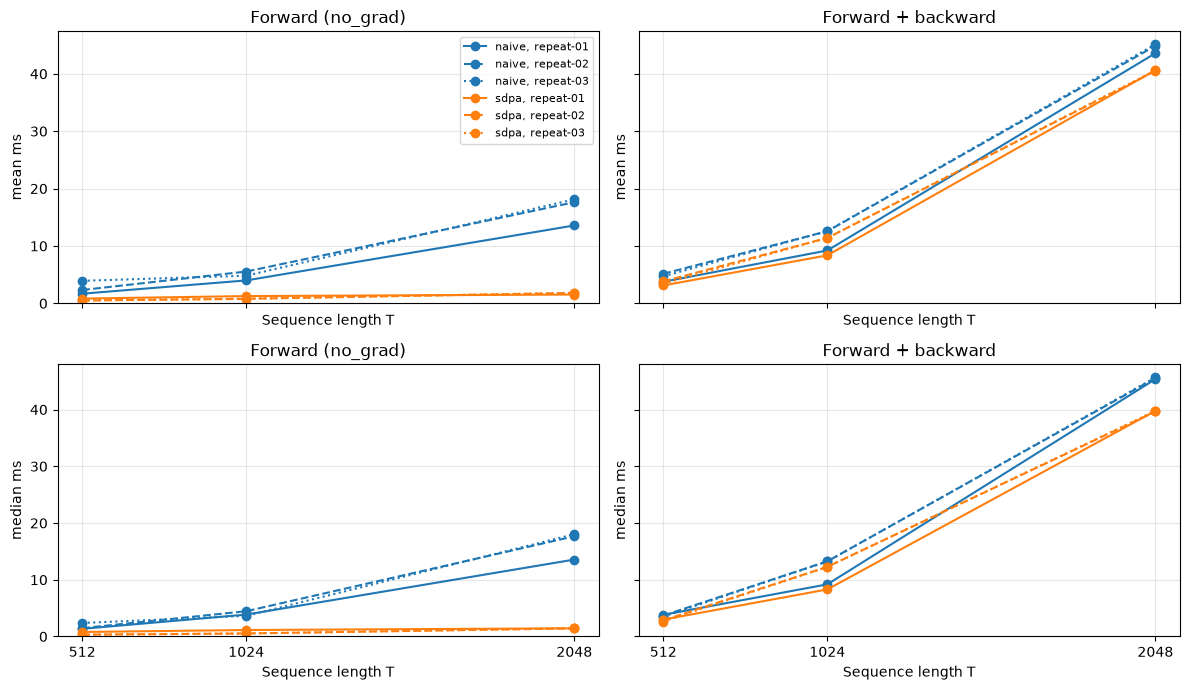

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=True, sharey="row")
for row, metric in enumerate(["mean_ms", "median_ms"]):
    for col, workload in enumerate(["forward", "forward_backward"]):
        ax = axes[row, col]
        data = core_times[core_times.workload == workload]
        for (backend, repeat), points in data.groupby(["backend", "repeat"]):
            points = points.sort_values("T")
            ax.plot(points["T"], points[metric], marker="o",
                    color=colors[backend], linestyle=styles[repeat], label=f"{backend}, {repeat}")
        ax.set_title("Forward (no_grad)" if workload == "forward" else "Forward + backward")
        ax.set(xlabel="Sequence length T", ylabel=metric.replace("_", " "), xticks=[512, 1024, 2048])
        ax.set_ylim(0, core_times[metric].max() * 1.05)
        ax.grid(alpha=0.3)
axes[0, 0].legend(fontsize=8)
fig.tight_layout()
plt.show()


## What stays for backward?

A separate, untimed forward records saved tensors. Views sharing one allocation are counted once.
`saved_total_MiB` includes saved inputs; `saved_extra_MiB` excludes preallocated Q/K/V and the naive mask.
This is **not peak memory**, total live memory or driver memory. With `no_grad`, nothing is saved for backward — temporary tensors still exist.

One FP32 attention matrix has shape [B,H,T,T] and takes `4*B*H*T*T` bytes.
Below: repeat 1, forward+backward. The JSON files also list the shapes sharing each saved storage.


,T,backend,saved_total_MiB,saved_extra_MiB
8,512,naive,9.75,9.5
11,512,sdpa,9.50,9.5
6,1024,naive,36.00,35.0
9,1024,sdpa,35.00,35.0
7,2048,naive,138.00,134.0
10,2048,sdpa,134.00,134.0


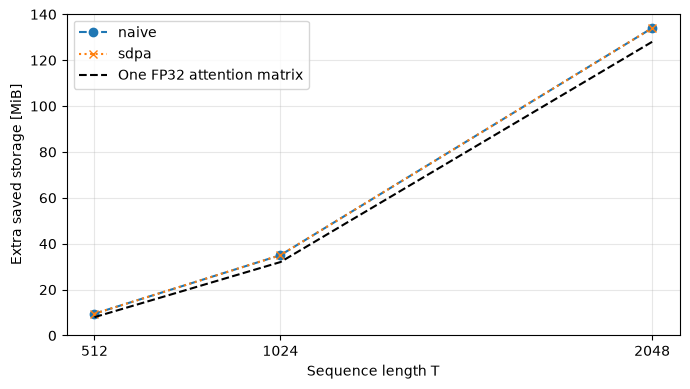

In [14]:
core_saved = core_times[(core_times.workload == "forward_backward") &
                        (core_times["repeat"] == "repeat-01")].sort_values(["T", "backend"])
display(core_saved[["T", "backend", "saved_total_MiB", "saved_extra_MiB"]].round(3))
fig, ax = plt.subplots(figsize=(7, 4))
for backend, points in core_saved.groupby("backend"):
    ax.plot(points["T"], points["saved_extra_MiB"], marker="o" if backend == "naive" else "x",
            linestyle="--" if backend == "naive" else ":",
            color=colors[backend], label=backend)
lengths = [512, 1024, 2048]
ax.plot(lengths, [4 * 2 * 4 * T**2 / 2**20 for T in lengths], "k--", label="One FP32 attention matrix")
ax.set(xlabel="Sequence length T", ylabel="Extra saved storage [MiB]", xticks=lengths)
ax.set_ylim(bottom=0)
ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()
plt.show()


## Short takeaways

At T=2048, attention alone is 8.82–9.84x faster with SDPA by mean time without autograd (9.39–12.36x by median). Forward + backward improves only 1.07–1.11x by mean. Smaller shapes vary more between runs; we keep all samples.

For backward, both versions save 134 MiB of extra storage: a 128 MiB attention matrix and 6 MiB of Q/K/V copies. Naive also saves the preallocated 4 MiB mask (138 MiB total vs 134 MiB). The extra-storage curves overlap — this is what we measured, not a plotting error.

So SDPA helps much more here without autograd. This is an attention-core result, not the speedup of a whole GPT training step. We have not measured temporary peak memory; zero tensors saved under no_grad does not mean zero memory use.
